# Casen: Din elregning - efter lektion 3

Et gennemgående eksempel, der vokser med kurset. Efter hver lektion får casen et nyt kapitel, som bruger *præcis* de værktøjer, du lige har lært - på **rigtige, levende data** om elpriser og dansk økonomi.


> ⚠️ **Vigtigt**: Dette er **ikke** et eksempel på en eksamensopgave. Det er et eksempel på, hvad kursets værktøjer kan, når man sætter dem sammen. Formålet er inspiration og leg - ikke pensum ud over det, I allerede har lært.


### Sådan læser du casen

* Hvert kapitel hører til én lektion og bruger kun værktøjer fra lektionerne til og med den.
* Celler markeret **Maskinrummet** henter data fra internettet (Energi Data Service og Danmarks Statistik). Du behøver ikke forstå koden i dem - de afleverer bare tallene. Kan de ikke nå internettet, bruger de automatisk gemte tal, så notebooken altid virker.
* **Du må ændre i alt!** Ret et tal, og kør cellen igen med Shift+Enter (eller ▶). Hvis senere celler bruger resultatet, så kør også dem igen. Går noget i stykker, vælger du bare *Runtime → Restart session and run all* - så er du tilbage ved start.
* Hvert kapitel slutter med **Drej på knapperne** - konkrete forslag til, hvad du kan ændre. Det er der, det bliver sjovt.


# Kapitel 1 (efter lektion 1): Elprisen i dag

Strøm handles på en børs, time for time, dagen i forvejen. **Spotprisen** er den rå markedspris (før afgifter, transport og moms) - og den svinger voldsomt hen over døgnet. Lad os hente den seneste tilgængelige dags priser for Vestdanmark (DK1) og se på dem med lektion 1's værktøjer: et plot og en hældning.

In [1]:
#@title Maskinrummet: definerer funktionen hent_elpriser(omraade) (du behøver ikke forstå denne celle)
import requests, json
import numpy as np

_GEMTE_PRISER = [0.975, 0.959, 0.958, 0.937, 0.936, 0.984, 1.064, 1.1, 1.068, 0.942, 0.756, 0.496, 0.232, 0.125, 0.162, 0.348, 0.641, 0.863, 1.053, 1.273, 1.468, 1.458, 1.334, 1.239]
_GEMT_DATO = "2026-08-07"
_KILDE_FALLBACK = "gemte DK1-priser (fallback)"

def hent_elpriser(omraade):
    # Henter det nyeste døgns spotpriser (kr/kWh) for et prisområde, fx "DK1"
    try:
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"limit": 200, "sort": "TimeDK desc",
                                 "filter": json.dumps({"PriceArea": [omraade]})}, timeout=10)
        rec = r.json()["records"]
        dato = rec[0]["TimeDK"][:10]
        pr_time = {}
        for x in rec:
            if x["TimeDK"][:10] == dato:
                pr_time.setdefault(x["TimeDK"][11:13], []).append(x["DayAheadPriceDKK"])
        priser = [sum(v) / len(v) / 1000 for _, v in sorted(pr_time.items())]
        if len(priser) != 24:
            raise ValueError("ufuldstændigt døgn")
    except Exception:
        # Fallback returnerer ALTID de gemte DK1-priser - uanset hvilket område der blev bedt om.
        # Derfor får kalderen en ærlig kilde-label med retur, så DK2 (eller ethvert andet område)
        # aldrig kan fremstå som ægte data for det område i en graf eller et regnestykke.
        print(f"(Kunne ikke hente live data for {omraade} - viser gemte DK1-priser fra {_GEMT_DATO} i stedet)")
        return np.array(_GEMTE_PRISER), _GEMT_DATO, _KILDE_FALLBACK
    print(f"Hentede friske spotpriser for {dato} ({omraade})")
    return np.array(priser), dato, f"live {omraade}"

In [2]:
# Hent den seneste tilgængelige dags priser for Vestdanmark - funktionen kommer fra maskinrummet ovenfor
elpriser, dato, kilde_dk1 = hent_elpriser("DK1")

timer = np.arange(24)

Hentede friske spotpriser for 2026-08-14 (DK1)


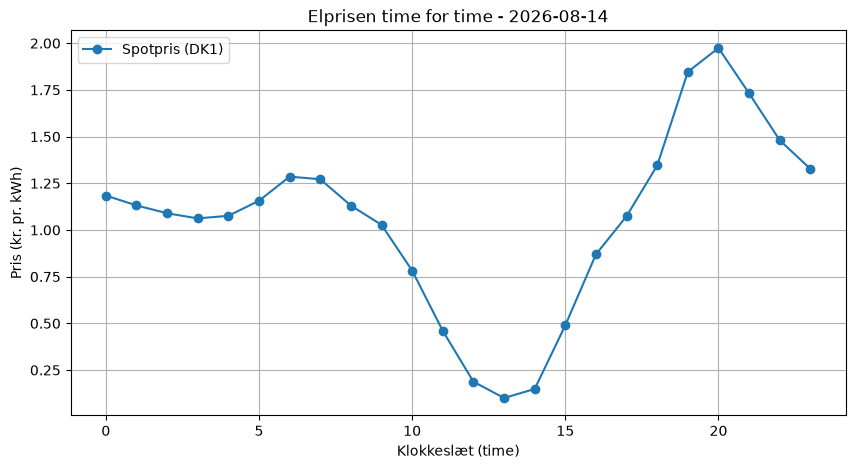

In [3]:
import matplotlib.pyplot as plt

# Plot døgnprofilen
plt.figure(figsize=(10, 5))
plt.plot(timer, elpriser, 'o-', label="Spotpris (DK1)")
plt.title(f"Elprisen time for time - {dato}")
plt.xlabel("Klokkeslæt (time)")
plt.ylabel("Pris (kr. pr. kWh)")
plt.legend()
plt.grid(True)
plt.show()

Elprisen følger samfundets rytme - og årstiden. Om vinteren er morgen- og aftentimerne typisk dyrest. Om sommeren kan solstrøm presse prisen helt i bund midt på dagen - nogle gange endda under nul. Kig på **din** graf: Hvornår er strømmen billigst i dag, og hvor går kurven stejlest op eller ned?

Præcis dét måler en **hældning** - ændringen i pris pr. time, som vi kender fra lektion 1:


In [4]:
# Hældningen mellem to klokkeslæt - som i lektion 1
x1, x2 = 6, 8
haeldning = (elpriser[x2] - elpriser[x1]) / (x2 - x1)

if haeldning > 0:
    print(f"Mellem kl. {x1} og kl. {x2} STIGER prisen: {haeldning:.3f} kr/kWh pr. time")
else:
    print(f"Mellem kl. {x1} og kl. {x2} FALDER prisen: {haeldning:.3f} kr/kWh pr. time")

# Prøv også eftermiddagen, hvor aftensspidsen bygger op
x1, x2 = 14, 20
haeldning = (elpriser[x2] - elpriser[x1]) / (x2 - x1)

if haeldning > 0:
    print(f"Mellem kl. {x1} og kl. {x2} STIGER prisen: {haeldning:.3f} kr/kWh pr. time")
else:
    print(f"Mellem kl. {x1} og kl. {x2} FALDER prisen: {haeldning:.3f} kr/kWh pr. time")

Mellem kl. 6 og kl. 8 FALDER prisen: -0.077 kr/kWh pr. time
Mellem kl. 14 og kl. 20 STIGER prisen: 0.304 kr/kWh pr. time


### Vest mod Øst - og resten af nabolaget

Elmarkedet er delt i prisområder, og funktionen kan hente dem alle - du skal bare give den navnet:

* `"DK1"` - Danmark **vest** for Storebælt (Jylland og Fyn - og Aalborg!)
* `"DK2"` - Danmark **øst** for Storebælt (Sjælland og København)
* `"NO2"` - det sydlige Norge (vandkraft!)
* `"SE3"` og `"SE4"` - det mellemste og sydlige Sverige
* `"DE"` - Tyskland

Lad os sammenligne de to danske områder:


Hentede friske spotpriser for 2026-08-14 (DK2)


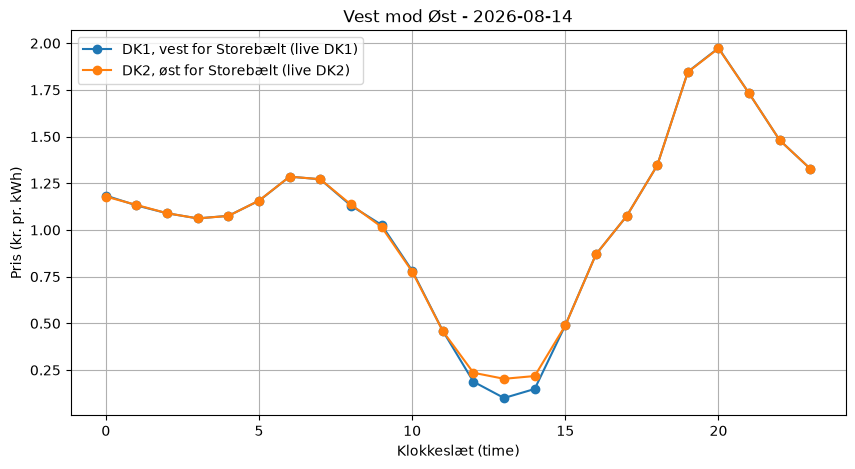

In [5]:
# Hent Østdanmark med samme funktion - bare et andet input
elpriser_dk2, dato_dk2, kilde_dk2 = hent_elpriser("DK2")

if kilde_dk1 == _KILDE_FALLBACK and kilde_dk2 == _KILDE_FALLBACK:
    print("Kunne ikke hente live data - sammenligningen mellem områder springes over i dag.")
else:
    plt.figure(figsize=(10, 5))
    plt.plot(timer, elpriser, 'o-', label=f"DK1, vest for Storebælt ({kilde_dk1})")
    plt.plot(timer, elpriser_dk2, 'o-', label=f"DK2, øst for Storebælt ({kilde_dk2})")
    plt.title(f"Vest mod Øst - {dato}")
    plt.xlabel("Klokkeslæt (time)")
    plt.ylabel("Pris (kr. pr. kWh)")
    plt.legend()
    plt.grid(True)
    plt.show()

Ligger de to kurver næsten oven i hinanden? Det er ikke en fejl: Når elkablerne mellem landsdelene ikke er fyldt op, deler hele Danmark én pris. På dage med meget vind eller stort forbrug skilles kurverne ad - så er der bogstaveligt talt forskel på at bo i Aalborg og i København.


#### Drej på knapperne

* **Prøv nabolaget**: Opret en ny celle (knappen `+ Kode`) og skriv fx `priser_norge, d, kilde = hent_elpriser("NO2")` - og plot dem ligesom ovenfor. Er norsk vandkraft billigere end dansk vind i dag?
* **Mål andre hældninger**: I hældnings-cellen: ret `x1, x2 = 6, 8` til to andre klokkeslæt (fx `10, 13`), og kør cellen igen.
* **Helt uden kode**: Aflæs på graferne - hvornår ville du starte opvaskemaskinen i dag? Og er svaret det samme i øst og vest?

# Kapitel 2 (efter lektion 2): Inflation og dine faste udgifter

Danmarks Statistik måler hver måned, hvad ting koster - **forbrugerprisindekset**. Med lektion 2's værktøjer (eksponentiel vækst og logaritmer) kan vi bruge de *rigtige* inflationstal til at regne på din egen fremtid.


In [6]:
#@title Maskinrummet: henter forbrugerprisindekset fra Danmarks Statistik
_GEMT_CPI = [100, 100.3, 101.4, 102.2, 103, 103.4, 105.4, 113.5, 117.2, 118.8, 121.1]
_CPI_AAR = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

def hent_forbrugerprisindeks():
    try:
        r = requests.post("https://api.statbank.dk/v1/data",
                          json={"table": "PRIS112", "format": "JSONSTAT",
                                "variables": [{"code": "HOVED", "values": ["1005"]},
                                              {"code": "Tid", "values": [str(a) for a in _CPI_AAR]}]},
                          timeout=10)
        vaerdier = r.json()["dataset"]["value"]
        print("Hentede friske tal fra Danmarks Statistik (tabel PRIS112)")
        return np.array(_CPI_AAR), np.array(vaerdier)
    except Exception:
        print("(Kunne ikke hente live data - viser gemte tal)")
        return np.array(_CPI_AAR), np.array(_GEMT_CPI)

aar, cpi = hent_forbrugerprisindeks()

Hentede friske tal fra Danmarks Statistik (tabel PRIS112)


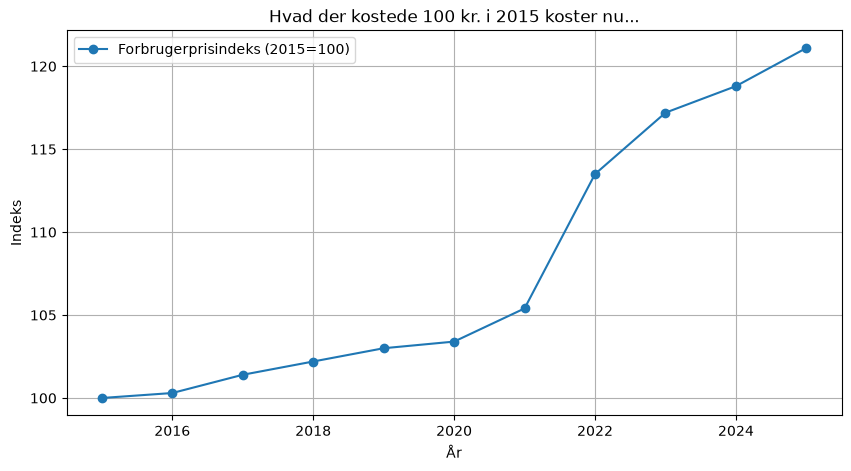

In [7]:
# Plot prisudviklingen (2015 = 100)
plt.figure(figsize=(10, 5))
plt.plot(aar, cpi, 'o-', label="Forbrugerprisindeks (2015=100)")
plt.title("Hvad der kostede 100 kr. i 2015 koster nu...")
plt.xlabel("År")
plt.ylabel("Indeks")
plt.legend()
plt.grid(True)
plt.show()

Læg mærke til, hvordan kurven knækker opad allerede i 2021 - og for alvor stikker af i 2022. Det er energi- og inflationskrisen, direkte i data. Den gennemsnitlige årlige inflation over hele perioden finder vi med en potens (samme logik som renters rente, bare baglæns):


In [8]:
# Gennemsnitlig årlig inflation over perioden
antal_aar = aar[-1] - aar[0]
r = (cpi[-1] / cpi[0]) ** (1 / antal_aar) - 1
print(f"Gennemsnitlig inflation {aar[0]}-{aar[-1]}: {r*100:.2f}% om året")

Gennemsnitlig inflation 2015-2025: 1.93% om året


In [9]:
# Hvad koster dine faste udgifter om 10 år, hvis det fortsætter?
budget = 8000  # dine faste udgifter i kr. pr. måned
om_10_aar = budget * (1 + r) ** 10
print(f"Faste udgifter på {budget} kr./md svarer om 10 år til {om_10_aar:.0f} kr./md i dagens tempo")

# Og hvornår er priserne fordoblet? (logaritmen - lektion 2)
fordobling = np.log(2) / np.log(1 + r)
print(f"Med {r*100:.2f}% årlig inflation fordobles priserne på {fordobling:.0f} år")

Faste udgifter på 8000 kr./md svarer om 10 år til 9688 kr./md i dagens tempo
Med 1.93% årlig inflation fordobles priserne på 36 år


#### Drej på knapperne

* **Dit eget budget**: Ret tallet i linjen `budget = 8000`, og kør cellen igen.
* **Kun kriseårene**: I inflations-cellen: udskift `cpi[0]` med `cpi[5]` og `aar[0]` med `aar[5]`, og kør igen - så regner du kun på 2020-2025. Hvor meget værre var dét?
* **Til eftertanke** (ingen kode): Hvad skulle din opsparing forrentes med, bare for at følge med inflationen?


# Kapitel 3 (efter lektion 3): Hvornår skal du vaske tøj?

Nu har vi optimeringsværktøjer! Lad os hente **en hel uges** elpriser og finde de billigste og dyreste timer - med `find_peaks`, `argmin` og `argmax` fra lektion 3. Og så regner vi ud, hvad planlægning faktisk er værd i kroner.


In [10]:
#@title Maskinrummet: henter den seneste uges elpriser
_GEMT_UGE = [1.257, 1.216, 1.157, 1.147, 1.155, 1.219, 1.328, 1.288, 1.19, 1.063, 0.921, 0.765, 0.704, 0.622, 0.645, 0.761, 0.891, 1.08, 1.211, 1.401, 1.456, 1.469, 1.43, 1.271, 1.265, 1.214, 1.171, 1.153, 1.151, 1.159, 1.154, 1.095, 1.05, 0.918, 0.729, 0.408, 0.12, 0.037, 0.027, 0.037, 0.326, 0.784, 1.067, 1.252, 1.351, 1.349, 1.335, 1.271, 1.266, 1.195, 1.172, 1.153, 1.146, 1.187, 1.13, 1.037, 0.913, 0.464, 0.023, 0.002, 0.015, 0.017, 0.015, 0.028, 0.062, 0.694, 1.094, 1.318, 1.385, 1.324, 1.249, 1.135, 1.036, 1.004, 0.981, 0.966, 0.987, 1.067, 1.257, 1.228, 1.121, 1.005, 0.824, 0.482, 0.156, 0.107, 0.16, 0.446, 0.766, 1.035, 1.21, 1.483, 1.522, 1.394, 1.292, 1.168, 1.145, 1.075, 1.032, 1.019, 1.064, 1.156, 1.238, 1.265, 1.207, 1.095, 0.928, 0.775, 0.653, 0.572, 0.628, 0.812, 0.941, 1.131, 1.253, 1.696, 1.791, 1.585, 1.381, 1.209, 1.154, 1.112, 1.1, 1.072, 1.032, 1.018, 1.039, 1.115, 1.039, 0.838, 0.484, 0.072, 0.02, 0.02, 0.018, 0.004, 0.058, 0.451, 0.896, 1.185, 1.264, 1.293, 1.256, 1.175, 1.109, 1.059, 0.953, 0.905, 0.873, 0.89, 0.919, 0.945, 0.813, 0.632, 0.189, 0.003, 0.001, 0.01, 0.011, 0.0, 0.0, 0.259, 0.598, 0.804, 0.936, 0.961, 1.021, 1.01]

def hent_ugens_elpriser():
    try:
        from datetime import date, timedelta
        slut = date.today()
        start = slut - timedelta(days=7)
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"start": str(start), "end": str(slut), "limit": 800,
                                 "filter": json.dumps({"PriceArea": ["DK1"]})}, timeout=15)
        rec = r.json()["records"]
        pr_time = {}
        for x in rec:
            pr_time.setdefault(x["TimeDK"][:13], []).append(x["DayAheadPriceDKK"])
        priser = [sum(v) / len(v) / 1000 for _, v in sorted(pr_time.items())]
        if len(priser) < 160:
            raise ValueError("for få timer")
        print(f"Hentede {len(priser)} timepriser for den seneste uge")
        return np.array(priser)
    except Exception:
        print("(Kunne ikke hente live data - viser gemte tal)")
        return np.array(_GEMT_UGE)

ugepriser = hent_ugens_elpriser()
ugetimer = np.arange(len(ugepriser))

Hentede 168 timepriser for den seneste uge


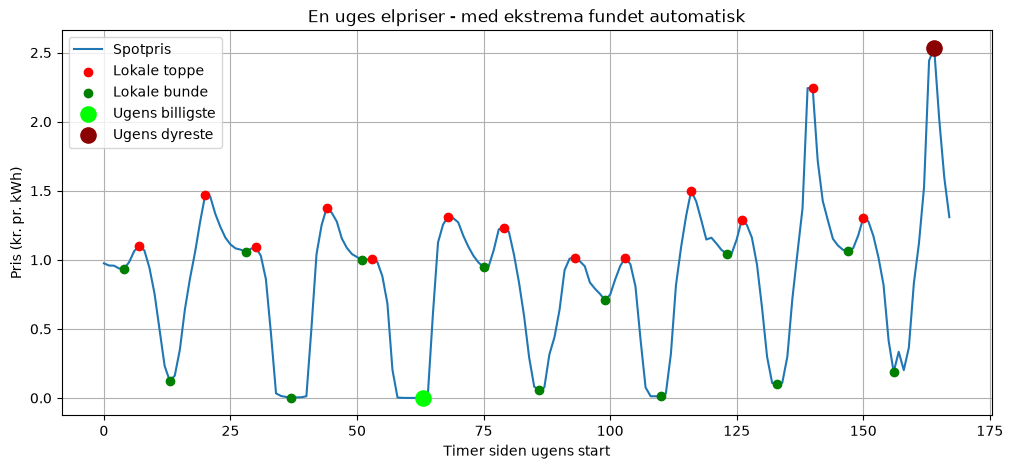

In [11]:
from scipy.signal import find_peaks

# Lokale toppe (dyre timer) og lokale bunde (billige timer)
dyre_timer, smid_vaek = find_peaks(ugepriser, distance=8)
billige_timer, smid_vaek = find_peaks(-ugepriser, distance=8)

# Ugens absolut billigste og dyreste time
billigst = np.argmin(ugepriser)
dyrest = np.argmax(ugepriser)

plt.figure(figsize=(12, 5))
plt.plot(ugetimer, ugepriser, label="Spotpris")
plt.scatter(dyre_timer, ugepriser[dyre_timer], color='red', label="Lokale toppe", zorder=5)
plt.scatter(billige_timer, ugepriser[billige_timer], color='green', label="Lokale bunde", zorder=5)
plt.scatter(billigst, ugepriser[billigst], color='lime', s=120, label="Ugens billigste", zorder=6)
plt.scatter(dyrest, ugepriser[dyrest], color='darkred', s=120, label="Ugens dyreste", zorder=6)
plt.title("En uges elpriser - med ekstrema fundet automatisk")
plt.xlabel("Timer siden ugens start")
plt.ylabel("Pris (kr. pr. kWh)")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Hvad er planlægning værd? En tørretumbler bruger ca. 2.5 kWh pr. tur
kwh_pr_tur = 2.5
pris_dum = kwh_pr_tur * ugepriser[dyrest]     # altid på det dyreste tidspunkt
pris_klog = kwh_pr_tur * ugepriser[billigst]  # altid på det billigste

print(f"Ugens dyreste time: {ugepriser[dyrest]:.2f} kr/kWh - ugens billigste: {ugepriser[billigst]:.2f} kr/kWh")
print(f"Én tumbling: {pris_dum:.2f} kr. på værste tidspunkt, {pris_klog:.2f} kr. på bedste")

# 3 ture om ugen, 52 uger om året - dette er et OPTIMISTISK loft, ikke en realistisk forventning:
# det kræver, at du rammer ugens billigste time hver eneste gang, hele året igennem
aarlig_besparelse = 3 * 52 * (pris_dum - pris_klog)
print(f"Et optimistisk overslag: op til {aarlig_besparelse:.0f} kr. om året, HVIS du altid rammer den billigste time - alene på tørretumbleren")

Ugens dyreste time: 2.53 kr/kWh - ugens billigste: -0.00 kr/kWh
Én tumbling: 6.33 kr. på værste tidspunkt, -0.00 kr. på bedste
Et optimistisk overslag: op til 988 kr. om året, HVIS du altid rammer den billigste time - alene på tørretumbleren


#### Drej på knapperne

* **Flere eller færre toppe**: I cellen med `find_peaks`: ret `distance=8` til `distance=3`, og kør cellen igen.
* **Dit eget apparat**: Ret `kwh_pr_tur = 2.5` til fx `40` (en elbil-opladning!), og kør cellen igen. Hvad er planlægning så værd om året?


### Fortsættelse følger
Casen vokser med kurset: næste kapitel låses op efter **lektion 4** - Varme-miksen